# Duelo: Random Forest × SVM — quem vai cancelar o plano?

## O contexto
Você é a pessoa de Machine Learning de uma **operadora de telecomunicações**. Todo mês, uma parte dos clientes
cancela o plano. No mercado, isso se chama **churn**, e custa caro: conquistar um cliente novo sai bem mais caro do que manter um antigo.

O **time de retenção** quer uma lista dos clientes com maior risco de cancelar para ligar para eles **antes** que saiam,
oferecendo desconto ou upgrade.

**Sua missão:** comparar os dois modelos que você aprendeu, **Random Forest** e **SVM**, e recomendar um ao gerente.

**Os dados:** *Telco Customer Churn*, um dos datasets mais conhecidos do Kaggle (publicado pela IBM): 7.043 clientes, 20 informações sobre cada um.


---
## Etapa 0 — Conhecer e limpar os dados

In [ ]:
import time
import warnings
warnings.filterwarnings("ignore")   # esconde avisos de métricas do "modelo preguiçoso"
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


| Coluna | Significado |
|---|---|
| `tenure` | há quantos **meses** a pessoa é cliente |
| `Contract` | tipo de contrato: mensal, 1 ano ou 2 anos |
| `MonthlyCharges` / `TotalCharges` | valor da mensalidade / total já pago |
| `InternetService` | tipo de internet: DSL, fibra ótica ou nenhuma |
| `PaymentMethod` | forma de pagamento (cheque eletrônico, cartão, débito automático…) |
| `TechSupport`, `OnlineSecurity`… | serviços adicionais contratados |
| `SeniorCitizen`, `Partner`, `Dependents` | idoso? tem cônjuge? tem dependentes? |
| `Churn` | **o que queremos prever:** cancelou (`Yes`) ou não (`No`) |

**0.1** Quantos clientes cancelaram?

In [ ]:
df["Churn"].value_counts(normalize=True)

,proportion
Churn,
No,0.73463
Yes,0.26537


**0.2 Um problema escondido.** A coluna `TotalCharges` deveria ser número, mas veio como **texto**:
11 clientes novos têm um espaço em branco no lugar do valor. O `pd.to_numeric` converte para número;
o parâmetro `errors` diz o que fazer com o que não for número. Queremos que vire **vazio** (`NaN`) para depois remover.


In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Valores vazios:", df["TotalCharges"].isna().sum())

df = df.dropna().drop(columns="customerID")     # remove os 11 vazios e o ID (não ajuda a prever)
y = (df.pop("Churn") == "Yes").astype(int)      # 1 = cancelou
X = pd.get_dummies(df, drop_first=True, dtype=int)  # texto → colunas 0/1 (one-hot)
print(f"{X.shape[0]} clientes | {X.shape[1]} colunas | {y.mean():.1%} cancelaram")

Valores vazios: 11
7032 clientes | 30 colunas | 26.6% cancelaram


<details><summary>Travou? Clique para ver uma dica</summary>

A opção que transforma o que não é número em `NaN` é `"coerce"`, com aspas.
</details>

**0.3 A função de avaliação.** Desta vez vamos olhar **mais de uma métrica**:

> **Lembrete de métricas (Unidade II)**
> - **Acurácia:** de todos os clientes, quantos o modelo acertou.
> - **Recall (do churn):** dos clientes que **realmente cancelaram**, quantos o modelo **pegou**. É o que interessa ao time de retenção: cliente que cancela e não foi avisado é cliente perdido.
> - **F1:** equilíbrio entre recall e precisão (dos que o modelo apontou, quantos cancelaram mesmo).
> - **Tempo:** quanto a validação cruzada levou. Em produção, tempo é custo.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = []

def avaliar(nome, modelo):
    inicio = time.time()
    r = cross_validate(modelo, X, y, cv=cv, scoring=["accuracy", "recall", "f1"])
    segundos = time.time() - inicio
    linha = {"Modelo": nome,
             "Acurácia": r["test_accuracy"].mean(),
             "Recall (churn)": r["test_recall"].mean(),
             "F1": r["test_f1"].mean(),
             "Tempo (s)": segundos}
    resultados.append(linha)
    print(f"{nome:<32} acurácia {linha['Acurácia']:.1%} | recall {linha['Recall (churn)']:.1%} | "
          f"F1 {linha['F1']:.1%} | {segundos:.1f}s")

---
## Etapa 1 — A linha de base: o "modelo preguiçoso"

Antes de qualquer modelo de verdade, sempre se pergunta: **e se eu chutasse a resposta mais comum?**
O `DummyClassifier` faz exatamente isso: diz que **ninguém** vai cancelar.

In [ ]:
avaliar("Chute: ninguém cancela", DummyClassifier(strategy="most_frequent"))

Chute: ninguém cancela           acurácia 73.4% | recall 0.0% | F1 0.0% | 0.1s


**1.1 O chute acertou cerca de 73%. Isso é bom? O que o recall de 0% significa para o time de retenção?**

*Sua resposta:* Não, não é bom. Os 73% não medem inteligência do modelo, apenas refletem o desbalanceamento da base: cerca de 73% dos clientes não cancelam, então quem sempre responde "ninguém cancela" acerta essa fatia por construção. A acurácia só tem valor quando comparada a esse piso.

O recall de 0% significa que, dos clientes que realmente cancelaram (cerca de 1.870), o modelo não avisou nenhum. Para o time de retenção, a lista de clientes em risco seria sempre vazia: ninguém receberia oferta ou contato antes de sair, e cada cancelamento seria uma surpresa, com toda a perda de receita recorrente.

Ou seja, o modelo tem uma acurácia respeitável no papel e valor operacional zero. Por isso, o critério de sucesso dos próximos modelos não é passar de 73%, e sim subir o recall e o F1 a partir de zero, sem deixar a precisão despencar.

---
## Etapa 2 — Random Forest

> **Lembrete:** muitas árvores diferentes votando. Não precisa escalar os dados.
> `RandomForestClassifier(n_estimators=..., max_depth=..., random_state=42)`

**2.1** Escreva a Random Forest com **300 árvores** e **profundidade máxima 8**.

In [ ]:
avaliar("Random Forest", RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42))

Random Forest                    acurácia 80.3% | recall 50.0% | F1 57.4% | 8.6s


<details><summary>Travou? Clique para ver uma dica</summary>

`RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42)`
</details>

---
## Etapa 3 — SVM

> **Lembrete:** o SVM decide por **distância**. Repare nas escalas:
> `tenure` vai de 1 a 72, `TotalCharges` vai até **8.684**, e as colunas do one-hot são 0 ou 1.

**3.1** Rode o SVM **sem** escalar:

In [ ]:
avaliar("SVM sem escala", SVC())

SVM sem escala                   acurácia 73.4% | recall 0.0% | F1 0.0% | 8.4s


**3.2 Compare o SVM sem escala com o chute da Etapa 1. O que aconteceu? Por quê?**

*Sua resposta:* O SVM sem escala teve exatamente o mesmo resultado do chute: acurácia 73,4%, recall 0% e F1 0%. Na prática, ele virou um modelo preguiçoso e prevê “ninguém cancela” para todos, mas ainda gastou 8,4s para isso.

O motivo é que o SVM decide por distância. TotalCharges (até 8.684) e tenure (até 72) têm valores enormes perto das colunas 0/1, então dominam o cálculo da distância e as demais variáveis quase não influenciam. Sem enxergar bem o conjunto das variáveis, o modelo não encontra uma fronteira útil e cai na classe mais comum. A solução é padronizar com StandardScaler, para todas as colunas ficarem na mesma escal

**3.3** Agora monte o SVM **com escala**, usando um pipeline:

In [ ]:
avaliar("SVM com escala", make_pipeline(StandardScaler(), SVC()))

SVM com escala                   acurácia 79.6% | recall 49.0% | F1 56.1% | 9.1s


<details><summary>Travou? Clique para ver uma dica</summary>

Igual à aula de SVM: `make_pipeline(StandardScaler(), SVC())`.
</details>

---
## Etapa 4 — O duelo

In [ ]:
pd.DataFrame(resultados).set_index("Modelo").style.format(
    {"Acurácia": "{:.1%}", "Recall (churn)": "{:.1%}", "F1": "{:.1%}", "Tempo (s)": "{:.1f}"})

,Acurácia,Recall (churn),F1,Tempo (s)
Modelo,,,,
Chute: ninguém cancela,73.4%,0.0%,0.0%,0.1
Random Forest,80.3%,50.0%,57.4%,8.6
SVM sem escala,73.4%,0.0%,0.0%,8.4
SVM com escala,79.6%,49.0%,56.1%,9.1


**4.1 Quem venceu em acurácia? E em recall? A diferença entre os dois é grande?**

*Sua resposta:* Em acurácia, a Random Forest venceu (80,3% contra 79,6% do SVM com escala). Em recall, também venceu (50,0% contra 49,0%). A diferença é pequena: cerca de 0,7 ponto em acurácia e 1 ponto em recall, o que não permite dizer que um modelo é claramente melhor que o outro. Ambos superam muito o chute, mas ainda deixam passar cerca de metade dos cancelamentos.

**4.2 Os dois pegam cerca de metade dos clientes que cancelam. Por que isso é um problema para o time de retenção?**

*Sua resposta:* Porque a outra metade dos clientes que cancelam passa despercebida: cerca de 935 dos aproximadamente 1.870 que saíram nunca entrariam na lista de risco. Para o time de retenção, cada um deles é um cliente perdido sem nenhuma chance de abordagem, com toda a receita recorrente que isso representa. O modelo é bem melhor que o chute, mas ainda deixa metade do problema sem solução, o que mostra que só treinar com as configurações padrão não basta. Ajustes como `class_weight="balanced"` ou a mudança do limiar de decisão podem aumentar o recall, ao custo de apontar mais clientes que não iriam cancelar.

---
## Etapa 5 — Uma decisão de negócio

Como só ~27% dos clientes cancelam, os modelos "preferem" dizer que o cliente fica. O parâmetro **`class_weight="balanced"`**
dá mais peso aos erros na classe rara: errar um cliente que cancela passa a custar mais caro durante o treino.
Os dois modelos aceitam esse parâmetro.

**5.1** Complete os dois modelos com `class_weight="balanced"`:

In [ ]:
avaliar("Random Forest balanceada",
        RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42))
avaliar("SVM balanceado",
        make_pipeline(StandardScaler(), SVC(class_weight="balanced")))

Random Forest balanceada         acurácia 76.3% | recall 77.3% | F1 63.5% | 9.7s
SVM balanceado                   acurácia 74.5% | recall 78.0% | F1 61.9% | 11.1s


<details><summary>Travou? Clique para ver uma dica</summary>

É o mesmo texto nos dois, com aspas: `"balanced"`.
</details>

In [ ]:
pd.DataFrame(resultados).set_index("Modelo").style.format(
    {"Acurácia": "{:.1%}", "Recall (churn)": "{:.1%}", "F1": "{:.1%}", "Tempo (s)": "{:.1f}"})

,Acurácia,Recall (churn),F1,Tempo (s)
Modelo,,,,
Chute: ninguém cancela,73.4%,0.0%,0.0%,0.1
Random Forest,80.3%,50.0%,57.4%,8.6
SVM sem escala,73.4%,0.0%,0.0%,8.4
SVM com escala,79.6%,49.0%,56.1%,9.1
Random Forest balanceada,76.3%,77.3%,63.5%,9.7
SVM balanceado,74.5%,78.0%,61.9%,11.1


**5.2 O que aconteceu com a acurácia e com o recall ao balancear? O que se ganhou e o que se perdeu?**

*Sua resposta:*

**5.3 Para o time de retenção, o que custa mais caro: ligar para um cliente que não ia sair, ou não ligar para um que vai sair? Qual versão você entregaria?**

*Sua resposta:* Ao balancear, a acurácia caiu e o recall subiu bastante. Na Random Forest, a acurácia foi de 80,3% para 76,3% (cerca de 4 pontos) e o recall de 50,0% para 77,3%. No SVM, a acurácia foi de 79,6% para 74,5% (cerca de 5 pontos) e o recall de 49,0% para 78,0%. O F1 também subiu nos dois (57,4% para 63,5% e 56,1% para 61,9%).

Ganhou-se a capacidade de pegar muito mais clientes que realmente cancelam: cerca de 77-78% contra 50%, ou seja, quase 500 clientes a mais com chance de serem abordados pela retenção. Perdeu-se acurácia e precisão, porque os modelos passaram a apontar mais clientes como risco e alguns deles não iriam cancelar (mais alarmes falsos).

Essa troca vale a pena quando perder um cliente custa mais caro que uma abordagem de retenção desnecessária. Por isso a acurácia menor não significa modelo pior: o modelo balanceado é mais útil para o time de retenção.

---
## Etapa 6 — Por que os clientes cancelam?

O gerente não quer só a lista: quer saber **o que fazer** para reduzir o churn.
A Random Forest diz quais colunas ela mais usou. O SVM com kernel RBF **não** oferece isso de forma direta.

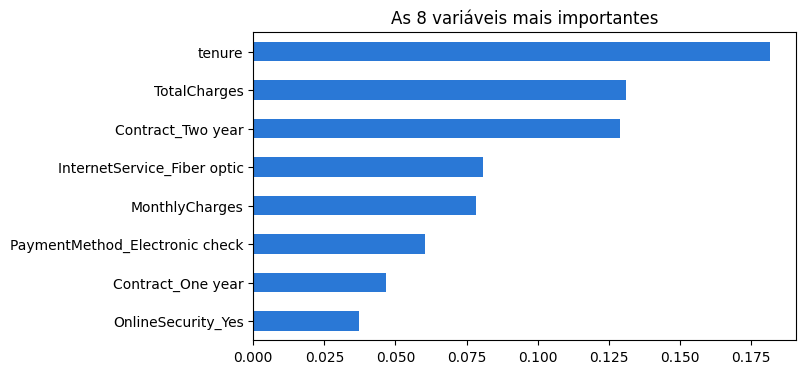

In [ ]:
rf = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42).fit(X, y)
importancia = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(8)
importancia.plot.barh(color="#2a78d6", figsize=(7, 4), title="As 8 variáveis mais importantes")
plt.show()

**6.1 Cite 3 variáveis do topo e uma ação que a empresa poderia tomar a partir delas.**

*Sua resposta:* Três variáveis do topo do gráfico são `tenure`, `Contract_Two year` e `InternetService_Fiber optic`.

**`tenure` (tempo de casa):** é a variável mais importante. Clientes novos cancelam mais, então a empresa pode criar um programa de acompanhamento nos primeiros meses, com contato proativo e ofertas de boas-vindas.

**`Contract_Two year` (contrato de 2 anos):** o tipo de contrato pesa muito. A empresa pode oferecer desconto ou benefícios para migrar clientes do contrato mensal para contratos de 1 ou 2 anos.

**`InternetService_Fiber optic` (internet de fibra):** o serviço de fibra aparece como relevante, então vale investigar a qualidade e o preço desse serviço e oferecer suporte ou plano ajustado a quem o usa.

A importância mostra quais colunas o modelo mais usou, mas não o sentido do efeito nem uma relação de causa. Por isso, as ações acima são hipóteses a validar com os dados (por exemplo, comparando a taxa de churn entre os grupos) antes de investir.

<details><summary>Extra para quem terminou: SVM linear</summary>

Com muitas colunas 0/1, às vezes uma fronteira reta basta. Teste:

```python
avaliar("SVM linear", make_pipeline(StandardScaler(), SVC(kernel="linear")))
```
Ele bate o SVM rbf? E a Random Forest?
</details>

---
## Sua recomendação ao gerente

In [ ]:
pd.DataFrame(resultados).set_index("Modelo").sort_values("Recall (churn)", ascending=False).style.format(
    {"Acurácia": "{:.1%}", "Recall (churn)": "{:.1%}", "F1": "{:.1%}", "Tempo (s)": "{:.1f}"})

,Acurácia,Recall (churn),F1,Tempo (s)
Modelo,,,,
SVM balanceado,74.5%,78.0%,61.9%,11.1
Random Forest balanceada,76.3%,77.3%,63.5%,9.7
Random Forest,80.3%,50.0%,57.4%,8.6
SVM com escala,79.6%,49.0%,56.1%,9.1
Chute: ninguém cancela,73.4%,0.0%,0.0%,0.1
SVM sem escala,73.4%,0.0%,0.0%,8.4


**Em até 4 frases, para alguém que não é da área: qual modelo você recomenda, com qual ajuste, e por quê?**

*Sua resposta:* Recomendo a Random Forest com o ajuste de balanceamento (`class_weight="balanced"`). Ela identifica cerca de 77% dos clientes que vão cancelar, contra apenas 50% do modelo padrão, o que dá ao time de retenção a chance de abordar quase 500 clientes a mais antes de saírem. Ela também teve o melhor equilíbrio entre acertos e alarmes falsos (F1 de 63,5%) e foi mais rápida que o SVM, além de mostrar quais fatores mais pesam no cancelamento, como o tempo de casa e o tipo de contrato. O preço é que alguns clientes que não iriam cancelar também serão abordados, o que vale a pena se uma ação de retenção custar menos do que perder o cliente.